In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
DATA_PATH = Path(r"C:\Users\admin\OneDrive\Máy tính\BÀI TẬP HK3\MAY HOC\MAY_HOC_NHOM\Do_An_Cuoi_Ky\DATA\raw\diabetes_012_health_indicators_BRFSS2015.csv")

df = pd.read_csv(DATA_PATH)

In [3]:
print("Kích thước: ",df.shape)

Kích thước:  (253680, 22)


In [4]:
# kiểm tra trùng lặp
print("Trùng: ",df.duplicated().sum())

Trùng:  23899


In [5]:
# Phân phối target
target_count=df["Diabetes_012"].value_counts().sort_index()
print("Đếm lớp: ",target_count)
print("")
target_percent=df["Diabetes_012"].value_counts(normalize=True)*100
print("Tỷ lệ %: ",target_percent)

Đếm lớp:  Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

Tỷ lệ %:  Diabetes_012
0.0    84.241170
2.0    13.933302
1.0     1.825528
Name: proportion, dtype: float64


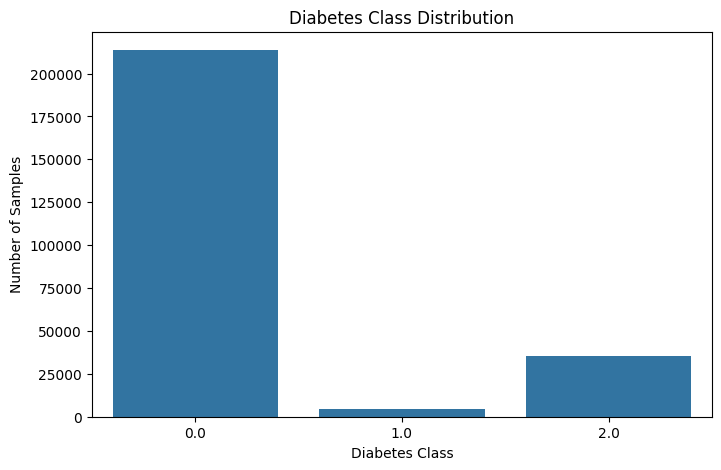

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Diabetes_012"
)

plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes Class")
plt.ylabel("Number of Samples")

plt.show()

In [7]:
# tách x và y
x=df.drop(columns=["Diabetes_012"])
y=df["Diabetes_012"]

print("Kích thước sau khi tách: ")
print("x: ",x.shape)
print("y: ",y.shape)

Kích thước sau khi tách: 
x:  (253680, 21)
y:  (253680,)


Tổng kết sau preprocessing thì ta đã biết dữ liệu sạch từ model trước nên không cần kiểm tra thêm vì cả 2 model đều sử dụng cùng dataset

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
#Chia dữ liệu thành các tập 
x_train, x_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Kích thước train: ", x_train.shape,"", y_train.shape)
print("Kích thước temp: ", x_temp.shape, "" , y_temp.shape)

Kích thước train:  (177576, 21)  (177576,)
Kích thước temp:  (76104, 21)  (76104,)


Dữ liệu được chia theo 70% train và 30% temp để từ temp có thể chia ra 50% validation và test

In [10]:
# Chia validation và test
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Kích thước validation: ",x_val.shape,"",y_val.shape)
print("Kích thước test: ",x_test.shape,"" ,y_test.shape)

Kích thước validation:  (38052, 21)  (38052,)
Kích thước test:  (38052, 21)  (38052,)


Dữ liệu test, validation được chia đều

Từ việc chia dataset trên không cần phải kiểm tra thêm vì sử dụng cùng dataset với model đầu tiên

In [11]:
# cài đặt thư viên thuật toán naive bayes
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()

In [12]:
# Huấn luyện mô hình trên tập train
model.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [13]:
# Xác suất Prior của từng Class
print("Class Prior:")
print(model.class_prior_)

# Mean của từng Feature theo từng Class
print("Mean:")
print(model.theta_)

# Variance của từng Feature theo từng Class
print("Variance:")
print(model.var_)

Class Prior:
[0.84241114 0.01825697 0.13933189]
Mean:
[[3.71657575e-01 3.78837104e-01 9.56862666e-01 2.77435892e+01
  4.30878657e-01 3.17530349e-02 7.16950104e-02 7.78397240e-01
  6.42955506e-01 8.20973047e-01 6.15206696e-02 9.49549441e-01
  7.93291085e-02 2.37056126e+00 2.94990374e+00 3.57973688e+00
  1.33242419e-01 4.33118081e-01 7.79015589e+00 5.10562731e+00
  6.20743756e+00]
 [6.21221468e-01 6.24614436e-01 9.84577421e-01 3.05876002e+01
  5.01542258e-01 5.33621221e-02 1.40037014e-01 6.85996299e-01
  6.03331277e-01 7.68969772e-01 4.62677360e-02 9.45712523e-01
  1.23689081e-01 2.98118445e+00 4.52467613e+00 6.18661320e+00
  2.74521900e-01 4.33066009e-01 9.08204812e+00 4.78285009e+00
  5.35410241e+00]
 [7.55031930e-01 6.69953925e-01 9.93492846e-01 3.19595021e+01
  5.21259397e-01 9.22722496e-02 2.22576995e-01 6.29698488e-01
  5.85239673e-01 7.57901544e-01 2.38865088e-02 9.60512489e-01
  1.07064910e-01 3.28700186e+00 4.46863633e+00 7.94911487e+00
  3.71554442e-01 4.78619352e-01 9.37818285

In [14]:
print("Classes:", model.classes_)
print("Theta shape:", model.theta_.shape)
print("Variance shape:", model.var_.shape)

Classes: [0. 1. 2.]
Theta shape: (3, 21)
Variance shape: (3, 21)


In [15]:
# chạy thử trên tập validation
# Making predictions on Validation Set
y_val_pred = model.predict(x_val)

# Predict probabilities trả về xác suất dự đoán của từng lớp
y_val_proba = model.predict_proba(x_val)

# Display classes
print("Classes:", model.classes_)

# Display predictions
print("Predictions:", y_val_pred)

# Display probabilities
print("Probabilities:")
print(y_val_proba)

Classes: [0. 1. 2.]
Predictions: [0. 2. 0. ... 0. 2. 0.]
Probabilities:
[[9.93350699e-01 1.93841277e-03 4.71088863e-03]
 [3.43733851e-01 2.94605732e-02 6.26805576e-01]
 [9.98759242e-01 4.78441421e-04 7.62316919e-04]
 ...
 [9.95450682e-01 1.01962896e-03 3.52968906e-03]
 [1.61715787e-06 8.04996307e-04 9.99193387e-01]
 [9.99649573e-01 1.62652741e-04 1.87774591e-04]]


In [16]:
# kiểm tra trên một mẫu ngẫu nhiên
sample = x_val[0:1]

prediction = model.predict(sample)
probability = model.predict_proba(sample)

print("Predicted class:", prediction[0])
print("Class probabilities:", probability[0])

Predicted class: 0.0
Class probabilities: [0.9933507  0.00193841 0.00471089]


In [17]:
# so sánh với kết quả của validation
comparison = pd.DataFrame({
    "Actual": y_val,
    "Predicted": y_val_pred
})

comparison["Correct"] = (
    comparison["Actual"] == comparison["Predicted"]
)

print(comparison)

        Actual  Predicted  Correct
193443     0.0        0.0     True
81443      1.0        2.0    False
30951      0.0        0.0     True
206873     2.0        0.0    False
102650     0.0        0.0     True
...        ...        ...      ...
84070      0.0        2.0    False
249345     0.0        0.0     True
73848      0.0        0.0     True
41176      0.0        2.0    False
188021     0.0        0.0     True

[38052 rows x 3 columns]


In [18]:
# số lượng dự đoán đúng và sai
# Count correct predictions
correct = (y_val == y_val_pred).sum()

# Count incorrect predictions
incorrect = (y_val != y_val_pred).sum()

print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)


Correct predictions: 28828
Incorrect predictions: 9224


In [19]:
# tỷ lệ dự đoán đúng 
accuracy = (y_val == y_val_pred).mean()

print("Validation Accuracy:", accuracy)
print("Validation Accuracy (%):", accuracy * 100)

Validation Accuracy: 0.7575948701776516
Validation Accuracy (%): 75.75948701776515


accuracy cao nhưng vẫn chưa thể kết luận mô hình tốt hay không

In [20]:
# xác suất dự đoán cảu từng lớp
comparison["Probability_Class_0"] = y_val_proba[:, 0]
comparison["Probability_Class_1"] = y_val_proba[:, 1]
comparison["Probability_Class_2"] = y_val_proba[:, 2]

print(comparison.head(10))

        Actual  Predicted  Correct  Probability_Class_0  Probability_Class_1  \
193443     0.0        0.0     True             0.993351             0.001938   
81443      1.0        2.0    False             0.343734             0.029461   
30951      0.0        0.0     True             0.998759             0.000478   
206873     2.0        0.0    False             0.705278             0.190523   
102650     0.0        0.0     True             0.998103             0.000693   
97665      0.0        0.0     True             0.987778             0.002857   
110599     0.0        0.0     True             0.977176             0.003194   
62594      0.0        0.0     True             0.979858             0.003945   
58037      0.0        0.0     True             0.999563             0.000211   
9594       1.0        0.0    False             0.859055             0.016871   

        Probability_Class_2  
193443             0.004711  
81443              0.626806  
30951              0.000762  

In [21]:
# kiểm tra mô hình có đang học thuộc đáp án không
y_train_pred = model.predict(x_train)

train_accuracy = (
    y_train == y_train_pred
).mean()

val_accuracy = (
    y_val == y_val_pred
).mean()

print("Train Accuracy:", train_accuracy)
print("Validation Accuracy:", val_accuracy)

Train Accuracy: 0.7564929945488129
Validation Accuracy: 0.7575948701776516


accuracy của val và train tương đối giống nhau nên có thể thấy mô hình có khả năng tổng quát hóa tốt

In [22]:
# sử dụng confusion matrix để xem xét rõ hơn mô hình
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [23]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=model.classes_,
    normalize="true"
)

print(cm)

[[0.80412403 0.00723733 0.18863863]
 [0.51585014 0.0129683  0.47118156]
 [0.4111656  0.01508865 0.57374576]]


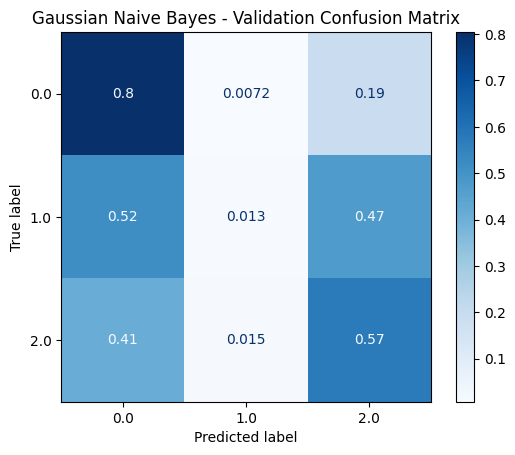

In [24]:
# Create confusion matrix display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

# Plot confusion matrix
disp.plot(cmap="Blues")

plt.title("Gaussian Naive Bayes - Validation Confusion Matrix")
plt.show()

từ biểu đồ ta thấy lớp 1 có tỷ lệ nhận diện đúng thấp nhất 

In [25]:
from sklearn.metrics import classification_report

In [26]:
# Generate classification report
report = classification_report(
    y_val,
    y_val_pred,
    labels=model.classes_,
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

 No Diabetes       0.91      0.80      0.85     32056
 Prediabetes       0.03      0.01      0.02       694
    Diabetes       0.32      0.57      0.41      5302

    accuracy                           0.76     38052
   macro avg       0.42      0.46      0.43     38052
weighted avg       0.81      0.76      0.78     38052



bảng đánh giá dựa trên nhãn thực tế và validation lớp có precision, recall và F1-score thấp nhất 

In [27]:
from sklearn.metrics import balanced_accuracy_score

In [28]:
# Calculate Balanced Accuracy
balanced_acc = balanced_accuracy_score(
    y_val,
    y_val_pred
)

print("Balanced Accuracy:", balanced_acc)
print("Balanced Accuracy (%):", balanced_acc * 100)

Balanced Accuracy: 0.46361269632417895
Balanced Accuracy (%): 46.361269632417894


In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_val, y_val_pred)

print("Accuracy:", accuracy)
print("Balanced Accuracy:", balanced_acc)

Accuracy: 0.7575948701776516
Balanced Accuracy: 0.46361269632417895


ta thấy balacnced accuracy giảm đáng kể so với accuracy cho thấy mô hình đang bị mất cân đối giữa các lớp

In [30]:
# nhũng mẫu bị dự đoán sai
# Create prediction comparison
comparison = pd.DataFrame({
    "Actual": y_val,
    "Predicted": y_val_pred
})

# Identify incorrect predictions
errors = comparison[
    comparison["Actual"] != comparison["Predicted"]
]

print("Total errors:", len(errors))

print(errors.head(10))

Total errors: 9224
        Actual  Predicted
81443      1.0        2.0
206873     2.0        0.0
9594       1.0        0.0
167257     0.0        2.0
109923     0.0        2.0
200270     2.0        0.0
244551     2.0        0.0
23278      0.0        2.0
164159     0.0        2.0
11138      2.0        0.0


từ bảng mẫu ta thấy lớp 1 bị dự đoán sai thành các lớp khác và nhãn dự đoán không hề xuất hiện lớp 1 vậy lớp 1 có thể đã bị bỏ qua khi dự đoán đa số

In [31]:
# Lấy những mẫu thực tế thuộc Class 1
class_1_mask = (y_val == 1)

# Dự đoán của những mẫu đó
class_1_predictions = y_val_pred[class_1_mask]

# Đếm mô hình đã dự đoán nhầm Class 1 thành lớp nào
pd.Series(class_1_predictions).value_counts()

0.0    358
2.0    327
1.0      9
Name: count, dtype: int64

In [32]:
# Lấy dữ liệu validation và nhãn thực tế
analysis_data = x_val.copy()

analysis_data["Actual"] = np.asarray(y_val)

# Chọn những feature có trong dataset
features_to_check = [
    "BMI",
    "HighBP",
    "HighChol",
    "PhysActivity",
    "Age",
    "GenHlth"
]

features_to_check = [
    col for col in features_to_check
    if col in analysis_data.columns
]

# Tính giá trị trung bình theo từng lớp
class_comparison = (
    analysis_data
    .groupby("Actual")[features_to_check]
    .mean()
)

print(class_comparison)

              BMI    HighBP  HighChol  PhysActivity       Age   GenHlth
Actual                                                                 
0.0     27.752340  0.369322  0.377371      0.780915  7.799725  2.375655
1.0     31.165706  0.616715  0.608069      0.657061  9.063401  3.025937
2.0     31.830441  0.742173  0.665032      0.630517  9.385515  3.310260


ta thấy được rằng features của lớp 1 và lớp 2 gần như tương đương nhau vậy đây có khả năng là lý do mô hình xác định nhầm

<Figure size 800x500 with 0 Axes>

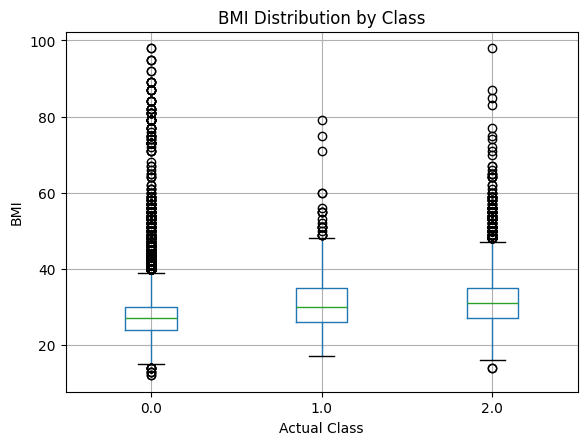

In [33]:
#Phân phối thực tế của BMI
feature = "BMI"
plt.figure(figsize=(8, 5))

analysis_data.boxplot(
        column=feature,
        by="Actual"
    )

plt.title(f"{feature} Distribution by Class")
plt.suptitle("")
plt.xlabel("Actual Class")
plt.ylabel(feature)

plt.show()

phân phối của BMI class 1 là quá ít so với các lớp còn lại

<Figure size 800x500 with 0 Axes>

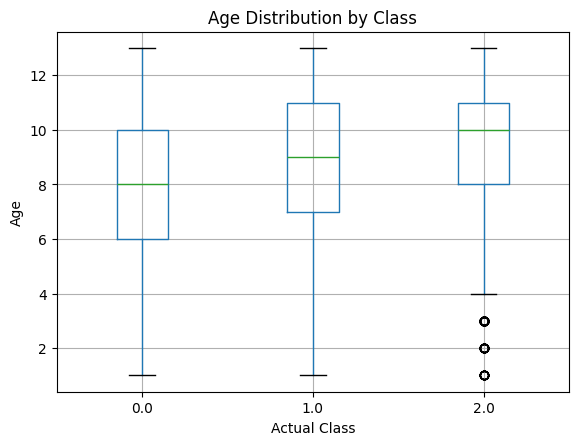

In [34]:
#Phân phối thực tế của Age
feature = "Age"
plt.figure(figsize=(8, 5))

analysis_data.boxplot(
        column=feature,
        by="Actual"
    )

plt.title(f"{feature} Distribution by Class")
plt.suptitle("")
plt.xlabel("Actual Class")
plt.ylabel(feature)

plt.show()

phân bố Age của class 1 lại nằm giữa age của 2 class còn lại

<Figure size 800x500 with 0 Axes>

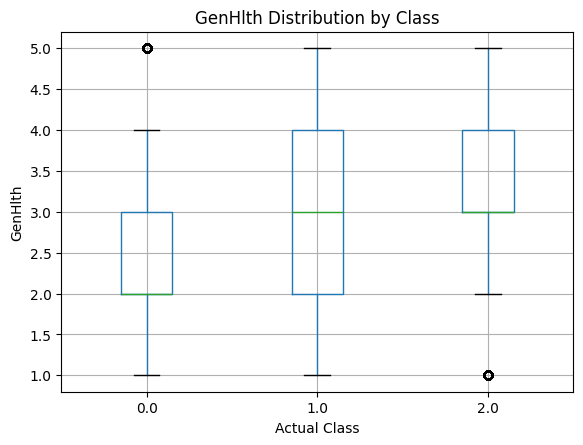

In [35]:
#Phân phối thực tế của GenHlth
feature = "GenHlth"
plt.figure(figsize=(8, 5))

analysis_data.boxplot(
        column=feature,
        by="Actual"
    )

plt.title(f"{feature} Distribution by Class")
plt.suptitle("")
plt.xlabel("Actual Class")
plt.ylabel(feature)

plt.show()

phân bố genhlth của class 1 bao trọn các class còn lại

từ 3 sơ đồ trên ta thấy sự phân bố các feature trong mẫu của class 1 gần như không cần thiết khi sự phân chia rõ rệt của class 0 và 2 đã phần nào phân định rõ rệt các dự đoán 

In [36]:
# kiểm tra xác suất tiên nghiệm
# Xác suất tiên nghiệm mà GaussianNB đã học
prior_comparison = pd.DataFrame({
    "Class": model.classes_,
    "Prior Probability": model.class_prior_
})

print(prior_comparison)

   Class  Prior Probability
0    0.0           0.842411
1    1.0           0.018257
2    2.0           0.139332


xác suất tiên nghiệm cho thấy class 1 hầu như không có

In [37]:
# tỷ lệ lớp trong tập train
train_distribution = (
    pd.Series(np.asarray(y_train))
    .value_counts(normalize=True)
    .sort_index()
)

print(train_distribution)

0.0    0.842411
1.0    0.018257
2.0    0.139332
Name: proportion, dtype: float64


tỷ lệ lớp 1 trong tập train cũng vô cùng thấp

In [38]:
#Thí nghiệm loại bỏ ảnh hưởng của Prior
# Mô hình mới với Prior bằng nhau
model_equal = GaussianNB(
    priors=[1/3, 1/3, 1/3]
)

# Huấn luyện trên cùng tập Train
model_equal.fit(x_train, y_train)

# Dự đoán trên Validation
y_val_pred_equal = model_equal.predict(x_val)

In [39]:
# đánh giá lại recall từng lớp
print(classification_report(
    y_val,
    y_val_pred_equal,
    labels=[0, 1, 2],
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))

              precision    recall  f1-score   support

 No Diabetes       0.93      0.70      0.80     32056
 Prediabetes       0.03      0.12      0.05       694
    Diabetes       0.31      0.65      0.42      5302

    accuracy                           0.68     38052
   macro avg       0.42      0.49      0.42     38052
weighted avg       0.83      0.68      0.73     38052



Recall Class 1 vẫn rất thấp, vấn đề có thể nằm nhiều hơn ở khả năng phân biệt các lớp thông qua Likelihood.

In [40]:
# Chỉ lấy những mẫu thực tế thuộc Class 1
class_1_samples = x_val[
    np.asarray(y_val) == 1
]

feature_names = (
    x_val.columns.tolist()
    if isinstance(x_val, pd.DataFrame)
    else [f"Feature_{i}" for i in range(x_val.shape[1])]
)

# Tính log-likelihood trung bình cho từng feature
likelihood_results = {}

for class_index, class_label in enumerate(model_equal.classes_):

    mean = model_equal.theta_[class_index]
    variance = model_equal.var_[class_index]

    log_likelihood = -0.5 * (
        np.log(2 * np.pi * variance)
        + ((class_1_samples - mean) ** 2 / variance)
    )

    likelihood_results[class_label] = (
        log_likelihood.mean(axis=0)
    )

likelihood_table = pd.DataFrame(
    likelihood_results,
    index=feature_names
)

print(likelihood_table)

                           0.0       1.0       2.0
HighBP               -0.826391 -0.697825 -0.765847
HighChol             -0.813562 -0.702521 -0.711970
CholCheck             0.588456  0.983029  1.158504
BMI                  -3.593838 -3.425225 -3.420880
Smoker               -0.724254 -0.726045 -0.730135
Stroke               -0.291588 -0.091391 -0.080568
HeartDiseaseorAttack -0.622705 -0.415773 -0.439082
PhysActivity         -0.736076 -0.676307 -0.675743
Fruits               -0.714746 -0.708765 -0.708593
Veggies              -0.597883 -0.571705 -0.571099
HvyAlcoholConsump     0.222529  0.276375  0.271389
AnyHealthcare        -0.021198 -0.013415 -0.073253
NoDocbcCost          -0.508456 -0.393773 -0.415111
GenHlth              -1.660322 -1.454441 -1.487483
MentHlth             -3.695222 -3.606370 -3.606434
PhysHlth             -4.065898 -3.840211 -3.827216
DiffWalk             -0.836272 -0.629214 -0.646588
Sex                  -0.724777 -0.724784 -0.723498
Age                  -2.515972 

In [41]:
# Lấy dữ liệu Validation
comparison_data = x_val.copy()

comparison_data["Actual"] = np.asarray(y_val)
comparison_data["Predicted"] = np.asarray(y_val_pred)

# Nhóm Class 1 bị dự đoán thành Class 2
class_1_misclassified_as_2 = comparison_data[
    (comparison_data["Actual"] == 1) &
    (comparison_data["Predicted"] == 2)
]

# Nhóm Class 2 được nhận diện đúng
class_2_correct = comparison_data[
    (comparison_data["Actual"] == 2) &
    (comparison_data["Predicted"] == 2)
]

# Chọn feature cần phân tích
features = [
    "BMI",
    "HighBP",
    "HighChol",
    "PhysActivity",
    "Age",
    "GenHlth"
]

# So sánh giá trị trung bình
comparison = pd.DataFrame({
    "Class 1 predicted as 2":
        class_1_misclassified_as_2[features].mean(),

    "Class 2 correctly predicted":
        class_2_correct[features].mean()
})

print(comparison)

              Class 1 predicted as 2  Class 2 correctly predicted
BMI                        32.614679                    33.042078
HighBP                      0.782875                     0.846154
HighChol                    0.749235                     0.744247
PhysActivity                0.562691                     0.514135
Age                         9.605505                     9.682446
GenHlth                     3.541284                     3.746220


GaussianNB gặp khó khăn nghiêm trọng trong việc phân biệt Class 1 (Prediabetes) với các lớp còn lại. Đặc biệt, 327 mẫu Class 1 bị phân loại thành Class 2 có đặc điểm trung bình gần giống nhóm Class 2 được phân loại đúng. Điều này cho thấy sự tương đồng về đặc trưng giữa hai nhóm có thể góp phần khiến mô hình ưu tiên Class 2. Ngoài ra, Prior thấp của Class 1 cũng tạo ra bất lợi, nhưng việc đặt Prior bằng nhau không cải thiện đáng kể Recall, cho thấy đây không phải nguyên nhân duy nhất.

CẢI THIÊN MÔ HÌNH

In [42]:
#Điều chỉnh var_smoothing
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

smoothing_values = np.logspace(-12, -6, 7)

results = []

for value in smoothing_values:

    # Khởi tạo mô hình
    model = GaussianNB(var_smoothing=value)

    # Huấn luyện
    model.fit(x_train, y_train)

    # Dự đoán Validation
    predictions = model.predict(x_val)

    # Đánh giá
    recalls = recall_score(
        y_val,
        predictions,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    results.append({
        "var_smoothing": value,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Recall Class 0": recalls[0],
        "Recall Class 1": recalls[1],
        "Recall Class 2": recalls[2]
    })

results_df = pd.DataFrame(results)

print(results_df)

   var_smoothing  Accuracy  Balanced Accuracy  Macro F1  Recall Class 0  \
0   1.000000e-12  0.757595           0.463613  0.428353        0.804124   
1   1.000000e-11  0.757595           0.463613  0.428353        0.804124   
2   1.000000e-10  0.757595           0.463613  0.428353        0.804124   
3   1.000000e-09  0.757595           0.463613  0.428353        0.804124   
4   1.000000e-08  0.757621           0.463623  0.428369        0.804155   
5   1.000000e-07  0.757674           0.463644  0.428400        0.804218   
6   1.000000e-06  0.757779           0.463163  0.427802        0.804405   

   Recall Class 1  Recall Class 2  
0        0.012968        0.573746  
1        0.012968        0.573746  
2        0.012968        0.573746  
3        0.012968        0.573746  
4        0.012968        0.573746  
5        0.012968        0.573746  
6        0.011527        0.573557  


In [43]:
best_result = results_df.loc[
    results_df["Macro F1"].idxmax()
]

print(best_result)

var_smoothing        1.000000e-07
Accuracy             7.576737e-01
Balanced Accuracy    4.636439e-01
Macro F1             4.283999e-01
Recall Class 0       8.042176e-01
Recall Class 1       1.296830e-02
Recall Class 2       5.737458e-01
Name: 5, dtype: float64


In [44]:
X_train_final = pd.concat(
    [x_train, x_val],
    axis=0
)

y_train_final = pd.concat(
    [y_train, y_val],
    axis=0
)

In [45]:
final_model = GaussianNB(
    var_smoothing=1e-7
)

final_model.fit(
    X_train_final,
    y_train_final
)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-07


In [46]:
y_test_pred = final_model.predict(x_test)

In [47]:
print("Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_test_pred))

print("Macro F1:",
      f1_score(y_test, y_test_pred, average="macro"))

print("Recall từng Class:",
      recall_score(
          y_test,
          y_test_pred,
          labels=[0, 1, 2],
          average=None
      ))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Accuracy: 0.7574897508672344
Balanced Accuracy: 0.4635521203383453
Macro F1: 0.4313351527454197
Recall từng Class: [0.80577133 0.02302158 0.56186345]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      0.81      0.85     32055
         1.0       0.04      0.02      0.03       695
         2.0       0.32      0.56      0.41      5302

    accuracy                           0.76     38052
   macro avg       0.42      0.46      0.43     38052
weighted avg       0.81      0.76      0.78     38052


Confusion Matrix:
[[25829   290  5936]
 [  387    16   292]
 [ 2251    72  2979]]


sau khi đã qua cải tiến và cho qua test set thì khả năng nhận diện class 1 vẫn không có sự thay đổi đáng kể trong mô hình 
Kết luận mô hình không thực sự phù hợp với dataset